<a href="https://colab.research.google.com/github/nuralfiyanti/ML_Ganjil2026/blob/main/JS07ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama : Nur Alfiyanti

NIM : 244107020055

Kelas : TI-3E

JS07 - Regresi

## **Praktikum 1**

**Download Dataset Terlebih Dahulu**

Berikut adalah langkah-langkah beserta penjelasan singkat dan snapshot kode program Python untuk melakukan praktikum regresi linier, mengacu pada kode program yang telah diberikan sebelumnya:

**Langkah 1: Persiapan Data**

Download dan letakkan file data yang akan digunakan pada direktori yang sama. Pastikan data telah disimpan dalam format CSV.

**Langkah 2: Import Library**

Import library NumPy dan Pandas yang digunakan untuk manipulasi data.



In [1]:
# import package
import numpy as np
import pandas as pd

**Langkah 3: Baca Data**

Baca data dari file CSV dengan menggunakan Pandas.



In [2]:
# baca data dari file CSV
data = pd.read_csv('dataset.csv')

**Langkah 4: Pemahaman Terhadap Data**


Tampilkan beberapa data awal, ukuran data, informasi data, dan deskripsi statistik data untuk memahami karakteristik data.

In [3]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


**Langkah 5: Visualisasi Data**


In [4]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

Import library Matplotlib dan Seaborn untuk visualisasi data.




/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


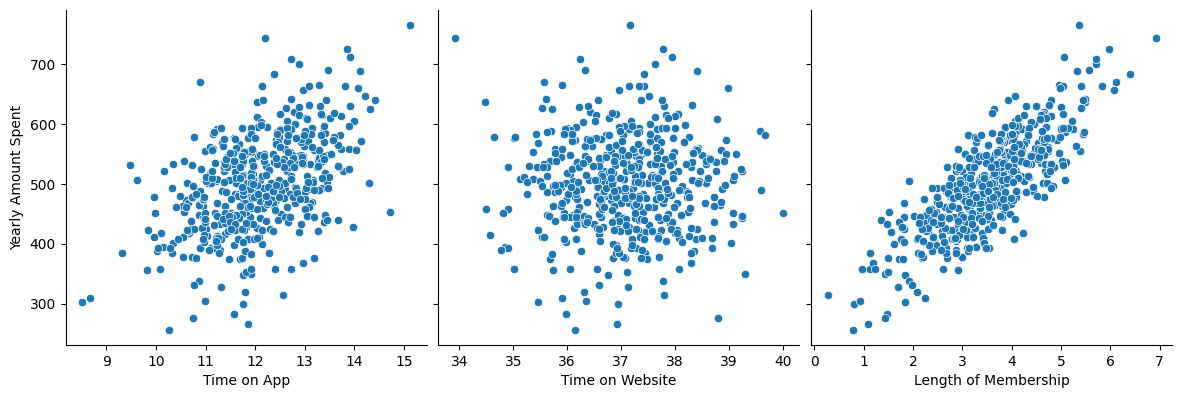

In [5]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

Gunakan pairplot untuk menampilkan hubungan antara variabel bebas dan variabel target dalam bentuk scatter plot.

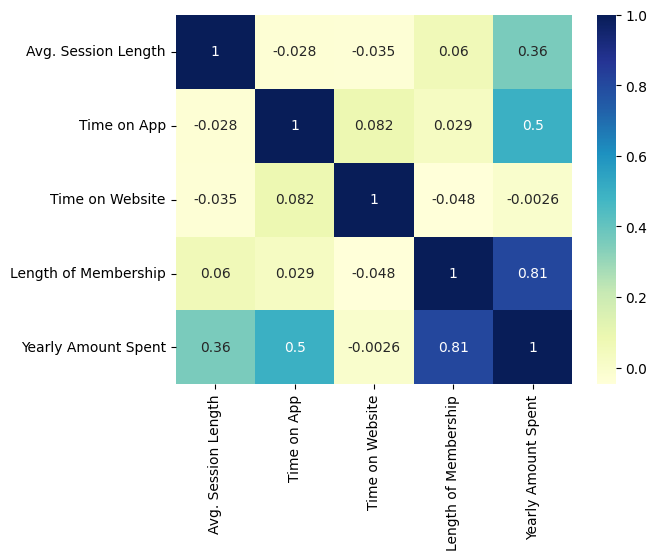

In [9]:

# Visualisasi korelasi dengan heatmap
corr = data.corr(numeric_only=True)

sns.heatmap(corr, cmap="YlGnBu", annot=True)
plt.show()


Gunakan heatmap untuk menampilkan matriks korelasi antara variabel-variabel dalam dataset. Semakin tinggi nilainya, semakin tinggi korelasinya.



**Langkah 6: Regresi Linier**

In [10]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

Pisahkan variabel bebas (X) dan variabel target (y).




In [11]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)


- Bagi data menjadi data latih (70%) dan data uji (30%) menggunakan train_test_split.

- Lakukan training model regresi linier menggunakan library StatsModels. Tambahkan konstanta (intercept) ke variabel bebas.

In [12]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

Visualisasikan garis regresi pada data latih.




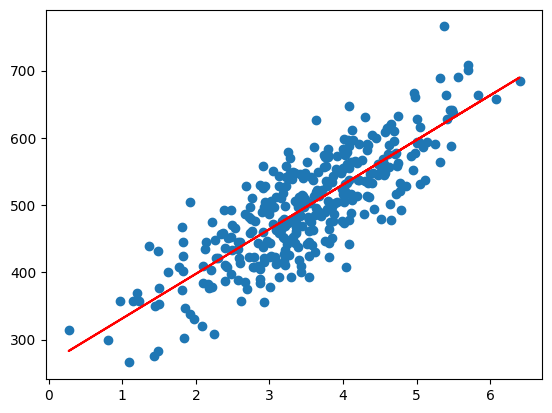

In [13]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

**Langkah 7: Analisis Residual**

In [14]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

Lakukan prediksi nilai y dari data latih dan hitung residual (selisih antara nilai sebenarnya dan nilai prediksi).




/tmp/ipykernel_1259/594495671.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


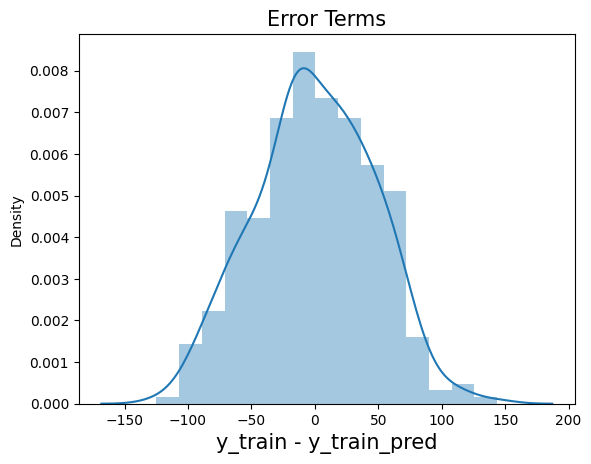

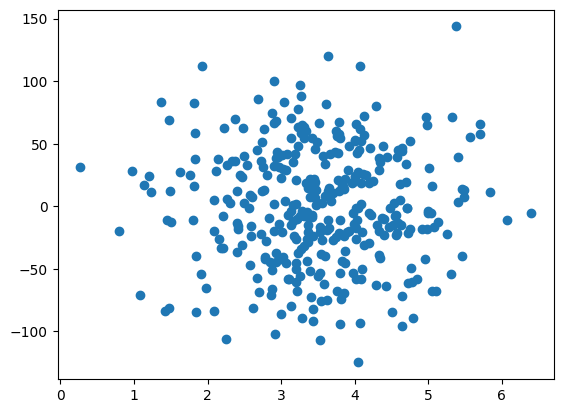

In [15]:
# Histogram residual
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.show()


Visualisasikan residual dalam bentuk histogram dan scatter plot untuk mengevaluasi distribusi dan pola error.

**Langkah 8: Prediksi pada Data Uji dan Evaluasi Model**

In [16]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

Lakukan prediksi pada data uji.




In [17]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)

Hitung nilai R-squared untuk mengukur kinerja model pada data uji.



**Langkah 9: Visualisasi Hasil**

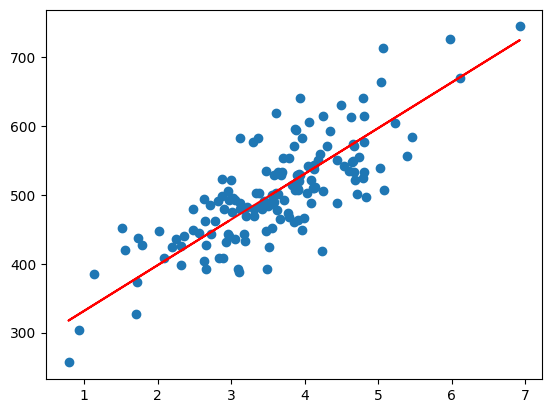

In [18]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

Visualisasikan data uji dan hasil prediksi dalam bentuk scatter plot.

Dengan mengikuti langkah-langkah di atas, Anda dapat melakukan analisis regresi linier pada data Anda, mengukur kinerja model, dan memvisualisasikan hasilnya.

## **Praktikum2**

**Download Dataset Terlebih Dahulu**

**1. Mengimpor Library:**

Lakukan import library yang diperlukan terlebih dahulu, termasuk NumPy, Matplotlib, dan pandas.





In [19]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

**2. Mengimpor Dataset:**


- Pastikan sudah mendownload file CSV 'Posisi_gaji.csv' dan letakkan dalam direktori yang sama. Ini adalah dataset yang akan digunakan dalam praktikum ini.

- Membaca dataset menggunakan pd.read_csv dan memilih fitur (variabel independen X) dan target (variabel dependen y).



In [20]:
# Mengimpor dataset (Pastikan Anda memiliki file CSV 'Posisi_gaji.csv' dalam direktori yang sama)
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

**Feature Scaling:**

Menggunakan StandardScaler untuk melakukan penskalaan fitur X dan target y. Ini diperlukan karena SVM sangat sensitif terhadap skala data.

In [21]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

**4. Fitting SVR ke Dataset:**

Lakukan pembuatan model SVR dengan kernel RBF (Radial Basis Function) dan melatihnya dengan data yang telah di-scaled.

In [22]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

**5. Visualisasi Hasil SVR:**

langkah selanjutkan, lakukan visualisasi Menggunakan grafik untuk memvisualisasikan hasil prediksi model SVR. Ini mencakup plotting data asli (titik-titik merah) dan kurva hasil prediksi (garis biru) untuk tingkat posisi yang bervariasi.

/tmp/ipykernel_1259/1841224750.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


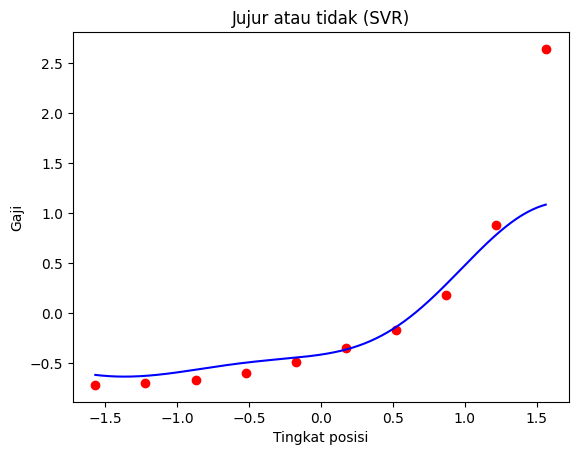

In [23]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

**6.
Prediksi Hasil:**


- Membuat array 2D yang berisi tingkat posisi yang akan diprediksi. Dalam contoh ini, tingkat posisi 6.5.

- Menskalakan fitur prediksi menggunakan sc_X.transform.

- Melakukan prediksi menggunakan model SVR yang telah dilatih.

- Mengembalikan hasil prediksi ke dalam skala aslinya menggunakan sc_y.inverse_transform.

In [24]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

**7. Menampilkan Hasil:**

Menampilkan hasil prediksi gaji untuk tingkat posisi 6.5 dalam kode




In [25]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


**8. Validasi Hasil:**

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]

Hasil output Gambar 3.10 adalah grafik dari model Support Vector Regression (SVR) yang telah dilatih untuk memprediksi gaji berdasarkan tingkat posisi. Grafik tersebut merupakan visualisasi dari hubungan antara tingkat posisi (x-axis) dan gaji (y-axis) setelah menerapkan model SVR.

**Grafik SVR:**


- Pada grafik tersebut, titik-titik merah mewakili data pengamatan asli yang digunakan untuk melatih model.

- Garis biru adalah hasil dari prediksi model SVR. Garis ini mencoba untuk mengikuti pola data asli sebaik mungkin dan merupakan representasi dari hubungan non-linear antara tingkat posisi dan gaji.

Hasil prediksi yang ditampilkan adalah prediksi gaji untuk tingkat posisi 6.5.
Hasilnya adalah sekitar $170,370.02. Ini berarti model SVR memperkirakan bahwa seseorang dengan tingkat posisi 6.5 akan memiliki gaji sekitar $170,370.02 berdasarkan pola hubungan yang ditemukan dalam data latihan.

Grafik ini memvisualisasikan bagaimana model SVR mencoba untuk menyesuaikan diri dengan data yang ada dan memberikan prediksi yang sesuai berdasarkan tingkat posisi yang diberikan (6.5 dalam hal ini). Dalam prakteknya, Anda dapat menggunakan model ini untuk membuat prediksi gaji berdasarkan tingkat posisi lainnya dengan mengganti nilai tingkat_posisi_prediksi.



**9. Evaluasi Model SVR**

Langkah terakhir adalah melakukan evaluasi model meliputi MAE, MSE dan R-squared

In [26]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


## **Tugas Praktikum Multiple Linear Regression**

**Dataset Medical Cost Personal**

Tujuan: membangun model Multiple Linear Regression untuk memprediksi biaya medis personal (charges) dari fitur usia, jenis kelamin, BMI, jumlah anak, status merokok, dan wilayah.

Notebook ini disusun mengikuti instruksi praktikum: memahami dataset, menentukan fitur dan target, membagi data train/test, melakukan preprocessing, melatih model, mengevaluasi dengan R², MSE, dan MAE, serta menampilkan visualisasi dan analisis.

Jalankan cell secara berurutan. Siapkan file insurance.csv dari materi praktikum. Hasil evaluasi dapat sedikit berbeda jika pembagian data atau pengaturan model berbeda.

**Langkah 1 Mengimpor Library**

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

print("Library berhasil diimpor.")

Library berhasil diimpor.


**Langkah 2 Membaca Dataset**


In [30]:
from pathlib import Path

file_path = Path("insurance.csv")

if not file_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        # Ambil file CSV yang diunggah
        csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Tidak ada file CSV yang diunggah.")
        file_path = Path(csv_files[0])
    except ImportError:
        raise FileNotFoundError(
            "Letakkan insurance.csv di folder yang sama dengan notebook, lalu jalankan kembali."
        )

data = pd.read_csv(file_path)
print("Dataset berhasil dibaca:", file_path)
data.head()

Dataset berhasil dibaca: insurance.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


**Langkah 3 Memahami Dataset**


In [31]:
print("Ukuran dataset (baris, kolom):", data.shape)

print("\\nInformasi dataset:")
data.info()

print("\\nStatistik deskriptif:")
display(data.describe())

print("\\nJumlah missing value setiap kolom:")
display(data.isnull().sum())

print("\\nJumlah baris duplikat:", data.duplicated().sum())

print("\\nNama kolom:")
print(data.columns.tolist())

Ukuran dataset (baris, kolom): (1338, 7)
\nInformasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
\nStatistik deskriptif:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


\nJumlah missing value setiap kolom:


,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


\nJumlah baris duplikat: 1
\nNama kolom:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


**Langkah 4 Visualisasi dan Eksplorasi Data**

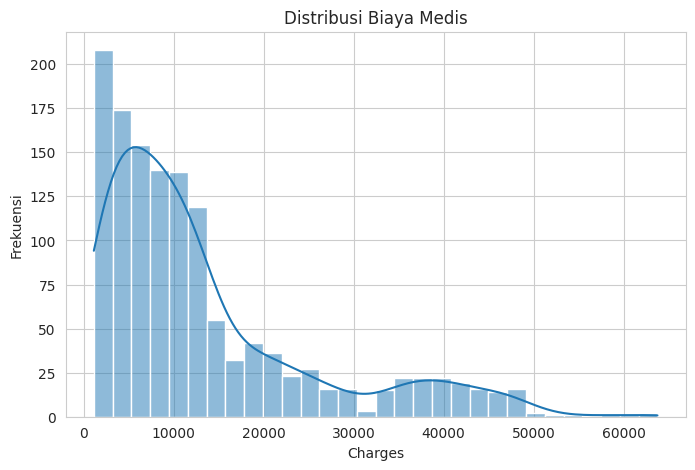

In [44]:
plt.figure(figsize=(8, 5))

sns.histplot(data['charges'], kde=True)

plt.title('Distribusi Biaya Medis')
plt.xlabel('Charges')
plt.ylabel('Frekuensi')

plt.show()

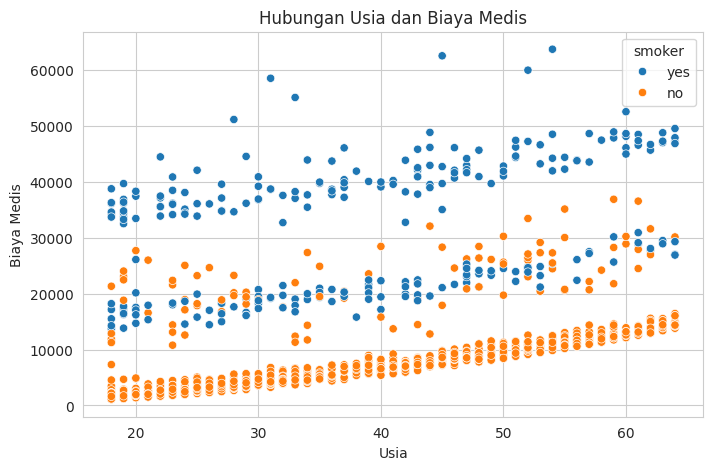

In [33]:
# Hubungan usia dan biaya medis berdasarkan status merokok
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x="age", y="charges", hue="smoker")
plt.title("Hubungan Usia dan Biaya Medis")
plt.xlabel("Usia")
plt.ylabel("Biaya Medis")
plt.show()

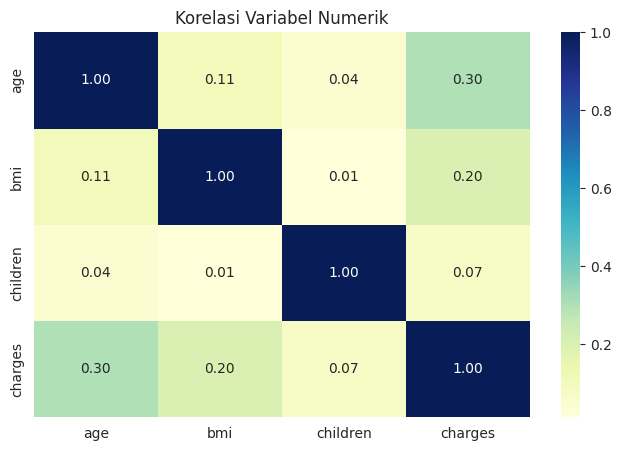

In [34]:
# Korelasi fitur numerik
numeric_data = data.select_dtypes(include=np.number)

plt.figure(figsize=(8, 5))
sns.heatmap(numeric_data.corr(), annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Korelasi Variabel Numerik")
plt.show()

**Langkah 5 Memisahkan Fitur dan Target**

In [35]:
# Fitur (X): seluruh kolom selain charges
# Target (y): charges
X = data.drop(columns=["charges"])
y = data["charges"]

print("Fitur (X):")
display(X.head())

print("\\nTarget (y):")
display(y.head())

Fitur (X):


,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


\nTarget (y):


,charges
0,16884.92400
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520


**Langkah 6 Membagi Data Training dan Testing**

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing :", X_test.shape[0])

Jumlah data training: 936
Jumlah data testing : 402


**Langkah 7 Preprocessing (Feature Scaling dan Encoding)**

In [37]:
numerical_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing berhasil disiapkan.")

Preprocessing berhasil disiapkan.


**Langkah 8 Membuat dan Melatih Model Multiple Linear Regression**

In [38]:
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

print("Model Multiple Linear Regression berhasil dilatih.")

Model Multiple Linear Regression berhasil dilatih.


**Langkah 9 Melakukan Prediksi pada Data Uji**

In [39]:
y_pred = model.predict(X_test)

hasil_prediksi = pd.DataFrame({
    "Biaya Aktual": y_test.to_numpy(),
    "Biaya Prediksi": y_pred
})

display(hasil_prediksi.head(10))

,Biaya Aktual,Biaya Prediksi
0,9095.06825,9016.367529
1,5272.17580,7019.976349
2,29330.98315,36870.834268
3,9301.89355,9518.537736
4,33750.29180,26974.030822
5,4536.25900,11080.846222
6,2117.33885,-40.617760
7,14210.53595,17192.233074
8,3732.62510,974.950536
9,10264.44210,11329.959373


**Langkah 10 Evaluasi Model**

In [40]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Evaluasi Model Multiple Linear Regression")
print("----------------------------------------")
print(f"MAE      : {mae:.2f}")
print(f"MSE      : {mse:.2f}")
print(f"RMSE     : {rmse:.2f}")
print(f"R-squared: {r2:.4f}")

Evaluasi Model Multiple Linear Regression
----------------------------------------
MAE      : 4145.45
MSE      : 33780509.57
RMSE     : 5812.10
R-squared: 0.7696


**Langkah 11 Memvisualisasikan Hasil Prediksi**

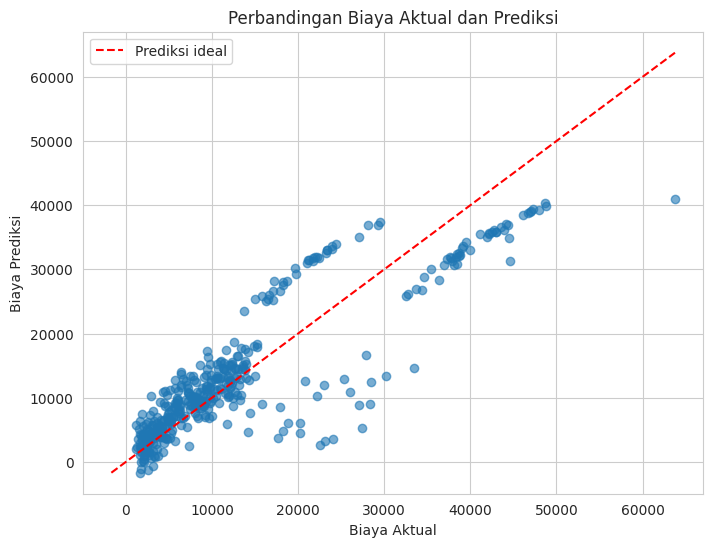

In [41]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

nilai_min = min(y_test.min(), y_pred.min())
nilai_max = max(y_test.max(), y_pred.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    "r--",
    label="Prediksi ideal"
)

plt.xlabel("Biaya Aktual")
plt.ylabel("Biaya Prediksi")
plt.title("Perbandingan Biaya Aktual dan Prediksi")
plt.legend()
plt.show()

**Langkah 12 Menampilkan Koefisien Model**

In [42]:
feature_names = model.named_steps["preprocessing"].get_feature_names_out()
coefficients = model.named_steps["regression"].coef_

tabel_koefisien = pd.DataFrame({
    "Fitur": feature_names,
    "Koefisien": coefficients
}).sort_values(by="Koefisien", ascending=False)

display(tabel_koefisien)

print("Intercept:", model.named_steps["regression"].intercept_)

,Fitur,Koefisien
6,cat__smoker_yes,11814.183611
0,num__age,3688.583190
1,num__bmi,2090.997834
7,cat__region_northeast,596.056589
2,num__children,514.023604
8,cat__region_northwest,109.121979
4,cat__sex_male,52.405911
3,cat__sex_female,-52.405911
10,cat__region_southwest,-330.266319
9,cat__region_southeast,-374.912249


Intercept: 20265.31718953714


**Analisis Hasil**

Berdasarkan hasil evaluasi model Multiple Linear Regression, diperoleh nilai MAE sebesar 3.943,24. Nilai tersebut menunjukkan bahwa rata-rata selisih absolut antara biaya medis aktual dan hasil prediksi adalah sekitar 3.943,24 satuan biaya. Nilai MSE sebesar 32.345.536,75 menunjukkan rata-rata kuadrat kesalahan prediksi, sedangkan nilai RMSE sebesar 5.687,31 menunjukkan besarnya kesalahan prediksi dalam satuan yang sama dengan biaya medis.

Nilai R-squared sebesar 0,7772 menunjukkan bahwa model mampu menjelaskan sekitar 77,72% variasi biaya medis personal pada data pengujian. Sementara itu, sekitar 22,28% variasi lainnya belum dapat dijelaskan oleh model. Hasil tersebut menunjukkan bahwa model Multiple Linear Regression memiliki kemampuan yang cukup baik dalam menjelaskan variasi biaya medis, meskipun hasil prediksinya masih memiliki kesalahan.

Berdasarkan hasil tersebut, model dapat digunakan untuk memperkirakan biaya medis personal berdasarkan variabel yang tersedia dalam dataset. Namun, hasil prediksi masih dapat dipengaruhi oleh faktor lain yang tidak tercakup dalam model.